# VisDrone2019-DET – Keşifsel Veri Analizi (EDA)

Bu defterde VisDrone2019-DET veri setinin görüntü/kutu sayıları, sınıf dağılımı, görüntü özellikleri ve kutu boyutları incelenmektedir.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Repo kök klasörünü bul (notebook notebooks/ içinden çalışıyor)
KOK = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(KOK))

from src.visdrone_okuma import bolum_oku, SINIF_ADLARI

FIGURLER = KOK / "reports" / "figures"
FIGURLER.mkdir(parents=True, exist_ok=True)

BOLUMLER = {
    "train": KOK / "data" / "VisDrone2019-DET-train",
    "val": KOK / "data" / "VisDrone2019-DET-val",
    "test-dev": KOK / "data" / "VisDrone2019-DET-test-dev",
}
print("Kök klasör:", KOK)

Kök klasör: c:\Users\betul\Documents\uyz_uav_object_detection


In [2]:
tablolar = []
for bolum, klasor in BOLUMLER.items():
    t = bolum_oku(klasor)
    t["bolum"] = bolum
    tablolar.append(t)

df = pd.concat(tablolar, ignore_index=True)
df.head()

VisDrone2019-DET-test-dev: 100%|██████████| 1610/1610 [00:01<00:00, 1344.29it/s]


,x,y,w,h,score,category,truncation,occlusion,sinif,dosya,bolum
0,684,8,273,116,0,0,0,0,ignored regions,0000002_00005_d_0000014,train
1,406,119,265,70,0,0,0,0,ignored regions,0000002_00005_d_0000014,train
2,255,22,119,128,0,0,0,0,ignored regions,0000002_00005_d_0000014,train
3,1,3,209,78,0,0,0,0,ignored regions,0000002_00005_d_0000014,train
4,708,471,74,33,1,4,0,1,car,0000002_00005_d_0000014,train


In [3]:
ozet = []
for bolum, klasor in BOLUMLER.items():
    goruntu_sayisi = len(list((klasor / "images").glob("*.jpg")))
    d = df[df["bolum"] == bolum]
    ozet.append({
        "bölüm": bolum,
        "görüntü": goruntu_sayisi,
        "kutu (toplam)": len(d),
        "kutu (1-10 sınıfları)": d["category"].between(1, 10).sum(),
        "ignored (0)": (d["category"] == 0).sum(),
        "others (11)": (d["category"] == 11).sum(),
        "kutusuz görüntü": goruntu_sayisi - d["dosya"].nunique(),
    })

ozet_df = pd.DataFrame(ozet)
ozet_df["görüntü başına kutu"] = (ozet_df["kutu (1-10 sınıfları)"] / ozet_df["görüntü"]).round(1)
ozet_df

,bölüm,görüntü,kutu (toplam),kutu (1-10 sınıfları),ignored (0),others (11),kutusuz görüntü,görüntü başına kutu
0,train,6471,353550,343205,8813,1532,0,53.0
1,val,548,40169,38759,1378,32,0,70.7
2,test-dev,1610,77547,75102,2180,265,0,46.6


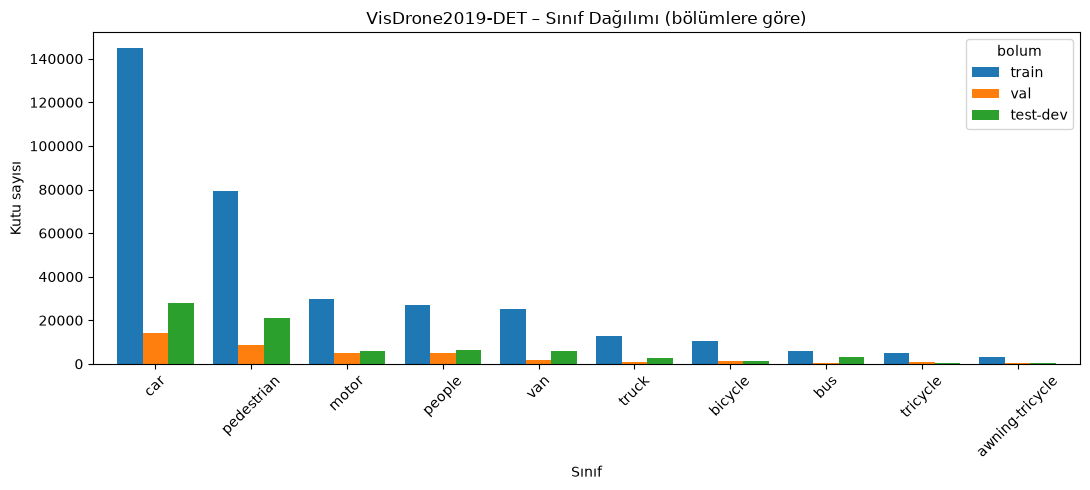

bolum,train,val,test-dev
sinif,,,
car,144867,14064,28074
pedestrian,79337,8844,21006
motor,29647,4886,5845
people,27059,5125,6376
van,24956,1975,5771
truck,12875,750,2659
bicycle,10480,1287,1302
bus,5926,251,2940
tricycle,4812,1045,530


In [4]:
siniflar = df[df["category"].between(1, 10)]
dagilim = pd.crosstab(siniflar["sinif"], siniflar["bolum"])
dagilim = dagilim[["train", "val", "test-dev"]].sort_values("train", ascending=False)

ax = dagilim.plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_title("VisDrone2019-DET – Sınıf Dağılımı (bölümlere göre)")
ax.set_xlabel("Sınıf")
ax.set_ylabel("Kutu sayısı")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIGURLER / "visdrone_sinif_dagilimi.png", dpi=150)
plt.show()

dagilim

In [5]:
from PIL import Image
from tqdm import tqdm

bilgiler = []
for bolum, klasor in BOLUMLER.items():
    for yol in tqdm(sorted((klasor / "images").glob("*.jpg")), desc=bolum):
        with Image.open(yol) as img:
            bilgiler.append({
                "bolum": bolum,
                "dosya": yol.stem,
                "genislik": img.width,
                "yukseklik": img.height,
                "mod": img.mode,
            })

goruntu_df = pd.DataFrame(bilgiler)

print("Renk modu dağılımı:")
print(goruntu_df["mod"].value_counts())
print()
print("En sık görüntü boyutları (genişlik x yükseklik):")
goruntu_df.groupby(["genislik", "yukseklik"]).size().sort_values(ascending=False).head(10)

test-dev: 100%|██████████| 1610/1610 [00:12<00:00, 128.86it/s]

Renk modu dağılımı:
mod
RGB    8629
Name: count, dtype: int64

En sık görüntü boyutları (genişlik x yükseklik):


genislik  yukseklik
1400      1050         2772
          788          2232
1360      765          1318
2000      1500          772
1916      1078          688
960       540           420
1920      1080          394
1398      1048           30
480       360             1
1344      756             1
dtype: int64

Kutu boyut grupları (% olarak):


boyut,küçük (<32²),orta (32²–96²),büyük (>96²)
bolum,,,
train,60.5,34.0,5.5
val,68.6,28.7,2.8
test-dev,67.7,29.1,3.2


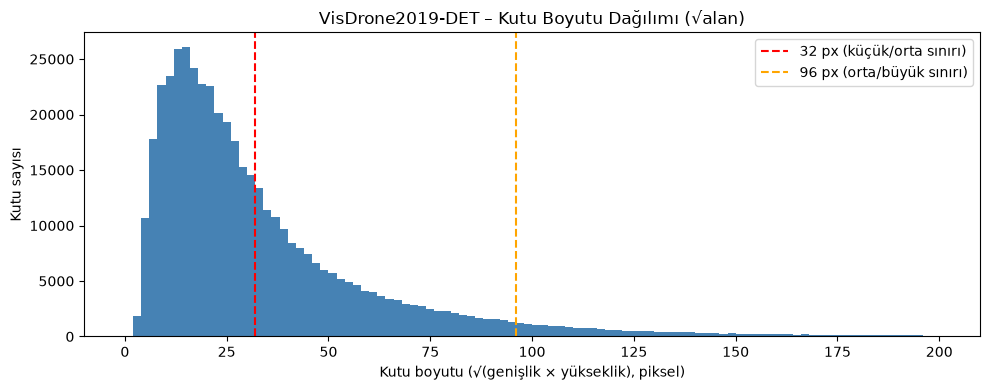

In [6]:
import numpy as np

kutular = df[df["category"].between(1, 10)].copy()
kutular["alan"] = kutular["w"] * kutular["h"]
kutular["boyut"] = pd.cut(
    kutular["alan"],
    bins=[0, 32**2, 96**2, float("inf")],
    labels=["küçük (<32²)", "orta (32²–96²)", "büyük (>96²)"],
    right=False,
)

boyut_oran = (pd.crosstab(kutular["bolum"], kutular["boyut"], normalize="index") * 100).round(1)
boyut_oran = boyut_oran.loc[["train", "val", "test-dev"]]
print("Kutu boyut grupları (% olarak):")
display(boyut_oran)

kutular["kenar"] = np.sqrt(kutular["alan"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(kutular["kenar"], bins=100, range=(0, 200), color="steelblue")
ax.axvline(32, color="red", linestyle="--", label="32 px (küçük/orta sınırı)")
ax.axvline(96, color="orange", linestyle="--", label="96 px (orta/büyük sınırı)")
ax.set_title("VisDrone2019-DET – Kutu Boyutu Dağılımı (√alan)")
ax.set_xlabel("Kutu boyutu (√(genişlik × yükseklik), piksel)")
ax.set_ylabel("Kutu sayısı")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURLER / "visdrone_kutu_boyutu.png", dpi=150)
plt.show()

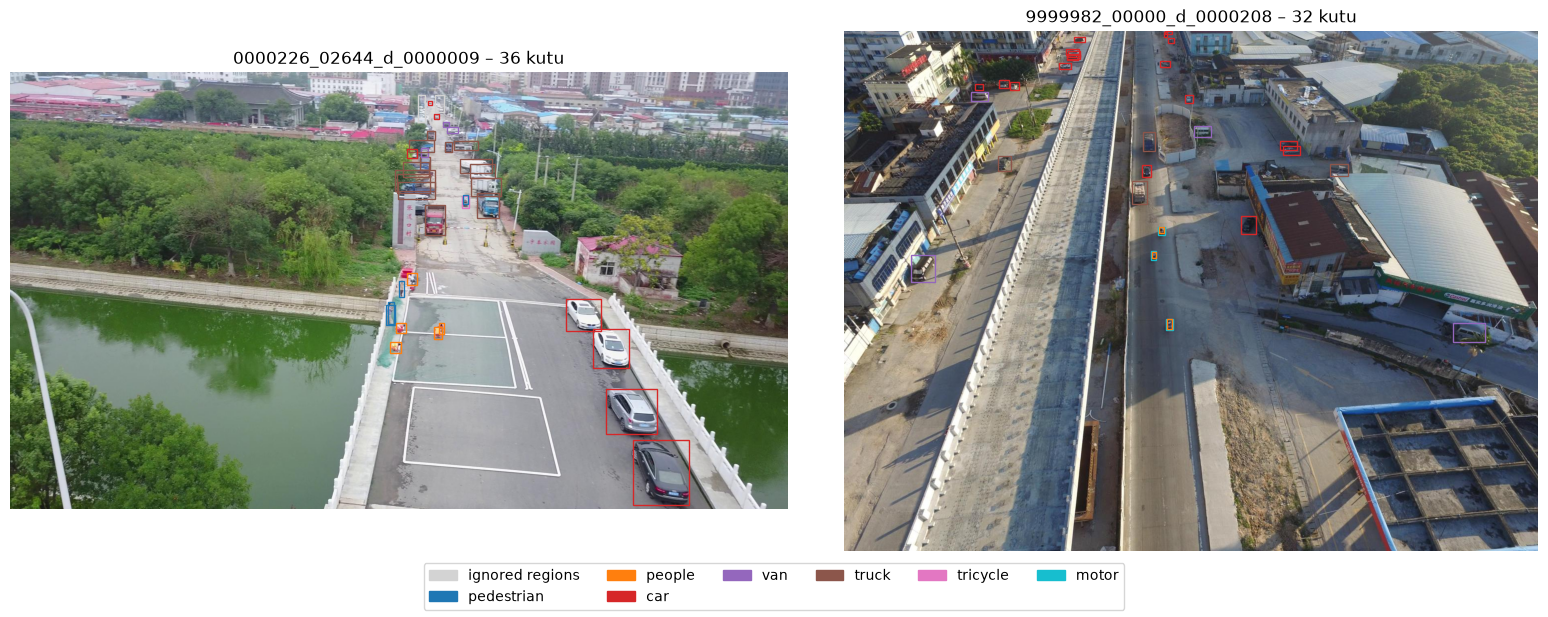

In [7]:
import matplotlib.patches as patches

# Her sınıfa sabit bir renk; ignored (0) ve others (11) gri
renkler = {k: plt.cm.tab10(k - 1) for k in range(1, 11)}
renkler[0] = "lightgray"
renkler[11] = "gray"

# Train'den rastgele ama her seferinde aynı 2 görüntü
rng = np.random.default_rng(42)
dosyalar = df.loc[df["bolum"] == "train", "dosya"].unique()
secilenler = rng.choice(dosyalar, size=2, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
kullanilan = set()

for ax, dosya in zip(axes, secilenler):
    img = Image.open(BOLUMLER["train"] / "images" / f"{dosya}.jpg")
    ax.imshow(img)
    etiketler = df[(df["bolum"] == "train") & (df["dosya"] == dosya)]
    for _, k in etiketler.iterrows():
        kutu = patches.Rectangle((k["x"], k["y"]), k["w"], k["h"],
                                 fill=False, edgecolor=renkler[k["category"]], linewidth=1)
        ax.add_patch(kutu)
        kullanilan.add(k["category"])
    ax.set_title(f"{dosya} – {len(etiketler)} kutu")
    ax.axis("off")

lejant = [patches.Patch(color=renkler[c], label=SINIF_ADLARI[c]) for c in sorted(kullanilan)]
fig.legend(handles=lejant, loc="lower center", ncol=6)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.savefig(FIGURLER / "visdrone_ornek_etiketler.png", dpi=150)
plt.show()

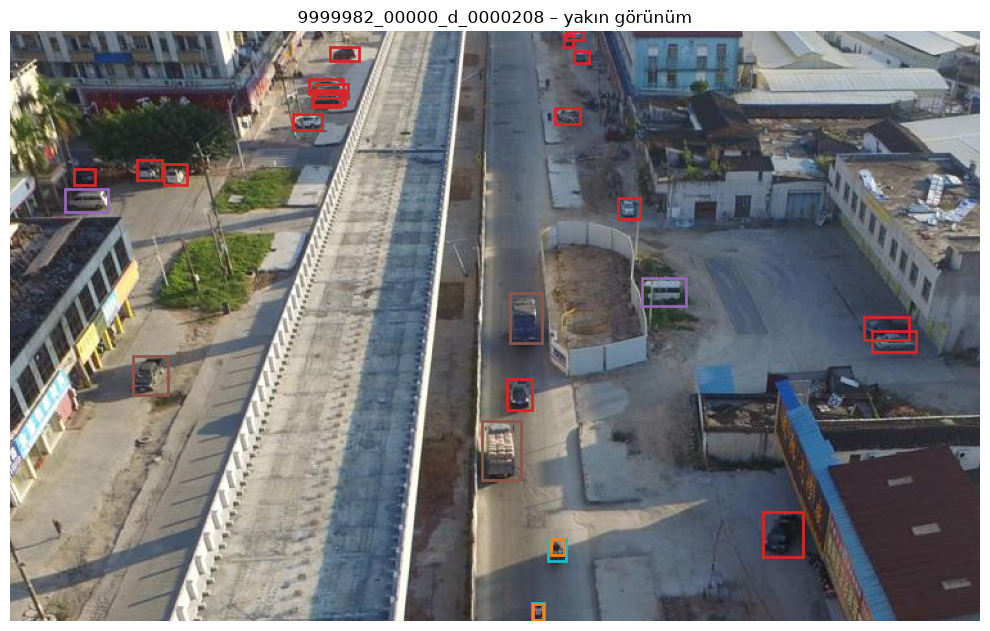

In [8]:
# Seçilen ikinci görüntüde arabaların bulunduğu bölgeye yakınlaş
dosya = secilenler[1]
img = Image.open(BOLUMLER["train"] / "images" / f"{dosya}.jpg")
etiketler = df[(df["bolum"] == "train") & (df["dosya"] == dosya)]
arabalar = etiketler[etiketler["category"] == 4]

# Arabaları kapsayan bölge (+50 piksel kenar payı)
x1 = max(arabalar["x"].min() - 50, 0)
y1 = max(arabalar["y"].min() - 50, 0)
x2 = min((arabalar["x"] + arabalar["w"]).max() + 50, img.width)
y2 = min((arabalar["y"] + arabalar["h"]).max() + 50, img.height)

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)
for _, k in etiketler.iterrows():
    ax.add_patch(patches.Rectangle((k["x"], k["y"]), k["w"], k["h"],
                                   fill=False, edgecolor=renkler[k["category"]], linewidth=2))
ax.set_xlim(x1, x2)
ax.set_ylim(y2, y1)
ax.set_title(f"{dosya} – yakın görünüm")
ax.axis("off")
plt.tight_layout()
plt.show()

## Bulgular (VisDrone2019-DET)

- **Veri sayısı:** 6.471 train / 548 val / 1.610 test-dev görüntü; her görüntünün etiket dosyası mevcut.
- **Eksik veri / etiket durumu:** Eksik veya boş etiket dosyası yok; her görüntüde en az bir nesne var. Ignored (0) ve others (11) kutuları train'deki kutuların yaklaşık %3'ü; ön işlemede çıkarılacak.
- **Yoğunluk:** Görüntü başına ortalama 47–71 nesne; sahneler çok kalabalık.
- **Sınıf dağılımı:** Belirgin dengesizlik. Car train kutularının %42'si, car + pedestrian %65'i; car ile awning-tricycle arasında yaklaşık 45 kat fark. Sınıf bazında AP raporlanmalı.
- **Renk ve boyut:** Tüm görüntüler RGB (gri görüntü yok). Boyutlar 480×360 ile 2000×1500 arasında değişiyor; 4:3 ve 16:9 oranlar karışık.
- **Kutu boyutu:** Kutuların %60–69'u küçük (<32² piksel), en sık kutu boyutu yaklaşık 15 piksel. 640 piksele yeniden boyutlandırmada nesneler yaklaşık 2,2 kat küçülüyor → SAHI gibi dilimleme yöntemleri ve daha yüksek giriş çözünürlüğü gerekçelendirilir.
- **Etiket kontrolü:** Örnek görüntülerde kutular nesnelerle örtüşüyor; format (sol üst x, y, genişlik, yükseklik) doğru yorumlanıyor.